# 03 Data Preprocessing

This notebook implements a reproducible preprocessing pipeline for the BotPrint behavioral dataset.

**Research requirements observed:**
- The original Excel file is never modified.
- All valid event records are preserved; invalid records are documented, not silently dropped.
- Missing values are not globally replaced with zero; they are handled per event type.
- Labels (`UserType`, `BotType`, `CoordinationGroupID`) and metadata are kept separate from behavioural measurements.
- No target leakage: labels are not used as behavioural features.
- No machine learning is performed in this notebook.

In [1]:
# Setup: imports, project-root resolution, output directories
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Resolve project root (kernel cwd is notebooks/)
_here = Path.cwd()
_root = _here
for _ in range(5):
    if (_root / "README.md").exists():
        break
    _root = _root.parent
PROJECT_ROOT = _root

# Make src/ importable
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from preprocessing import (
    load_data, add_datetime, sort_chronologically,
    validate_numeric_columns, find_invalid_measurements,
    handle_missing_by_event_type, preprocess, save_splits,
    split_labels_metadata_behaviour, ID_COLUMNS, LABEL_COLUMNS,
    METADATA_COLUMNS, BEHAVIOURAL_COLUMNS,
)

# Output directories
PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
ANALYSIS_DIR = PROJECT_ROOT / "reports" / "analysis"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed data: {PROCESSED_DIR}")
print(f"Figures: {FIGURES_DIR}")
print(f"Analysis: {ANALYSIS_DIR}")

Project root: C:\My KS\Research\BotPrint-Research
Processed data: C:\My KS\Research\BotPrint-Research\dataset\processed
Figures: C:\My KS\Research\BotPrint-Research\reports\figures
Analysis: C:\My KS\Research\BotPrint-Research\reports\analysis


## 1. Load the original Excel dataset

The dataset is loaded from `dataset/raw/BotPrint_Research_Dataset.xlsx` in read-only mode. The original file is never written to.

In [2]:
# 1. Load the original dataset
DATA_PATH = PROJECT_ROOT / "dataset" / "raw" / "BotPrint_Research_Dataset.xlsx"
print(f"Reading: {DATA_PATH}")
print(f"File exists: {DATA_PATH.exists()}")

df_original = load_data(DATA_PATH)
print(f"\nLoaded sheet: Events")
print(f"Original rows: {len(df_original):,}")
print(f"Original columns: {df_original.shape[1]}")
print(f"Unique sessions: {df_original['SessionID'].nunique()}")

# Keep an untouched reference copy
df_reference = df_original.copy(deep=True)

Reading: C:\My KS\Research\BotPrint-Research\dataset\raw\BotPrint_Research_Dataset.xlsx
File exists: True



Loaded sheet: Events
Original rows: 1,196
Original columns: 35
Unique sessions: 24


## 2. Preserve the original data

A deep copy (`df_reference`) is kept separate from the processing dataframe (`df`). All transformations are applied to `df` only, so the original data remains intact for audit and reproducibility.

In [3]:
# 2. Confirm original is preserved
df = df_original.copy(deep=True)
print(f"Processing dataframe rows: {len(df):,}")
print(f"Reference copy rows: {len(df_reference):,}")
print(f"Original file unmodified: {DATA_PATH.exists()}")

Processing dataframe rows: 1,196
Reference copy rows: 1,196
Original file unmodified: True


## 3. Convert Timestamp into a datetime representation

`Timestamp` is stored as epoch milliseconds. It is converted to a pandas `datetime64[ns]` column named `Timestamp_dt` for chronological sorting and temporal feature extraction.

In [4]:
# 3. Convert Timestamp to datetime
df = add_datetime(df, "Timestamp", "Timestamp_dt")
print(f"Timestamp_dt dtype: {df['Timestamp_dt'].dtype}")
print(f"Unparseable timestamps: {df['Timestamp_dt'].isna().sum()}")
if df['Timestamp_dt'].notna().any():
    print(f"Datetime range: {df['Timestamp_dt'].min()} to {df['Timestamp_dt'].max()}")
print(f"\nSample of converted timestamps:")
display(df[['SessionID', 'Timestamp', 'Timestamp_dt', 'EventType']].head(5))

Timestamp_dt dtype: datetime64[us]
Unparseable timestamps: 0
Datetime range: 2026-10-20 17:56:13.669000 to 2026-11-08 10:36:03.621000

Sample of converted timestamps:


,SessionID,Timestamp,Timestamp_dt,EventType
0,S-4fe30c98-b2c8-474a-b13d-68006c970e45,1792518973669,2026-10-20 17:56:13.669,click
1,S-4fe30c98-b2c8-474a-b13d-68006c970e45,1792518974893,2026-10-20 17:56:14.893,mousemove
2,S-4fe30c98-b2c8-474a-b13d-68006c970e45,1792518974577,2026-10-20 17:56:14.577,mousemove
3,S-4fe30c98-b2c8-474a-b13d-68006c970e45,1792518975029,2026-10-20 17:56:15.029,mousemove
4,S-4fe30c98-b2c8-474a-b13d-68006c970e45,1792518975733,2026-10-20 17:56:15.733,field_interaction


## 4. Sort events chronologically within SessionID

Events are sorted by `SessionID` then `Timestamp` so that temporal behaviour within each session is ordered correctly.

In [5]:
# 4. Sort chronologically within session
df = sort_chronologically(df, "SessionID", "Timestamp")
# Verify sort
df['prev_ts'] = df.groupby('SessionID')['Timestamp_dt'].shift(1)
out_of_order = (df['Timestamp_dt'] < df['prev_ts']).sum()
print(f"Events out of chronological order within session: {out_of_order}")
display(df[['SessionID', 'Timestamp_dt', 'prev_ts', 'EventType']].head(8))

Events out of chronological order within session: 0


,SessionID,Timestamp_dt,prev_ts,EventType
0,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:42.940,NaT,click
1,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:43.598,2026-11-03 15:56:42.940,mousemove
2,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:43.899,2026-11-03 15:56:43.598,mousemove
3,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:44.108,2026-11-03 15:56:43.899,field_interaction
4,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:45.858,2026-11-03 15:56:44.108,keypress
5,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:45.983,2026-11-03 15:56:45.858,keypress
6,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:46.137,2026-11-03 15:56:45.983,keypress
7,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,2026-11-03 15:56:46.611,2026-11-03 15:56:46.137,keypress


## 5. Validate numeric behavioural columns

Behavioural measurement columns are coerced to numeric. Non-convertible values become NaN and are reported; they are not silently dropped.

In [6]:
# 5. Validate numeric behavioural columns
df, num_report = validate_numeric_columns(df, BEHAVIOURAL_COLUMNS)
num_report_df = pd.DataFrame(num_report).T
display(num_report_df)
num_report_df.to_csv(ANALYSIS_DIR / "preprocessing_numeric_validation.csv")
total_newly_null = sum(v["newly_null_from_conversion"] for v in num_report.values())
print(f"\nTotal values newly turned to NaN by numeric conversion: {total_newly_null}")

,newly_null_from_conversion
Timestamp,0
ElapsedMs,0
IdleMs,0
X,0
Y,0
DX,0
DY,0
Speed,0
Acceleration,0
ClickIntervalMs,0



Total values newly turned to NaN by numeric conversion: 0


## 6-7. Handle missing values based on EventType (no global zero replacement)

Missing values are analysed per event type. Structural nulls (e.g., `X`/`Y` on non-mouse events) are expected and are **left as NaN** — they are **not** replaced with zero. Unexpected nulls (e.g., missing `X`/`Y` on a mouse event) are flagged.

**Rule:** missing values are never globally imputed with zero.

In [7]:
# 6-7. Missing values by event type
missing_flags = handle_missing_by_event_type(df)
mf_df = pd.DataFrame(missing_flags)
if len(mf_df) > 0:
    display(mf_df)
else:
    print("No unexpected per-event-type missing values flagged.")
mf_df.to_csv(ANALYSIS_DIR / "preprocessing_missing_by_event_type.csv", index=False)

print("\nStructural nulls (expected by event type, left as NaN):")
print("  - Mouse events: X/Y/Speed/Acceleration expected present, null on non-mouse")
print("  - Keyboard events: InterKeyIntervalMs/TypingCount expected present, null on non-keyboard")
print("  - Click events: ClickIntervalMs/ClickCount expected present, null on non-click")
print("  - Scroll events: ScrollDelta/ScrollSpeed/ScrollCount expected present, null on non-scroll")

total_nulls = int(df.isnull().sum().sum())
print(f"\nTotal null cells retained in cleaned data: {total_nulls:,}")
print("These are structural per event type and remain as NaN (not zero).")

No unexpected per-event-type missing values flagged.

Structural nulls (expected by event type, left as NaN):
  - Mouse events: X/Y/Speed/Acceleration expected present, null on non-mouse
  - Keyboard events: InterKeyIntervalMs/TypingCount expected present, null on non-keyboard
  - Click events: ClickIntervalMs/ClickCount expected present, null on non-click
  - Scroll events: ScrollDelta/ScrollSpeed/ScrollCount expected present, null on non-scroll

Total null cells retained in cleaned data: 23,610
These are structural per event type and remain as NaN (not zero).


## 8. Investigate negative or invalid measurements

Negative elapsed time, negative speed, and negative counts are physically impossible. They are flagged and the affected records are candidates for exclusion.

In [8]:
# 8. Investigate negative/invalid measurements
invalid_issues = find_invalid_measurements(df)
if invalid_issues:
    ii_df = pd.DataFrame(invalid_issues)
    display(ii_df)
    ii_df.to_csv(ANALYSIS_DIR / "preprocessing_invalid_measurements.csv", index=False)
else:
    print("No negative or invalid measurements found.")
    pd.DataFrame({"metric":["invalid_measurement_rows"], "value":[0]}).to_csv(ANALYSIS_DIR / "preprocessing_invalid_measurements.csv", index=False)

,column,n_negative,session_ids
0,Acceleration,214,"[S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8, S-171..."


## 9-10. Preprocess: preserve valid records, document exclusions

Records that are invalid (unparseable timestamp, negative speed, mouse event with null coordinates) are excluded and documented with reasons. All other valid records are preserved.

In [9]:
# 9-10. Run preprocessing pipeline
result = preprocess(df_original.copy(deep=True))
df_cleaned = result["cleaned"]
df_excluded = result["excluded"]
report = result["report"]

print(f"Original records: {report['n_original']:,}")
print(f"Excluded records: {report['n_excluded']:,}")
print(f"Cleaned records: {report['n_cleaned']:,}")

print("\nExclusion reasons:")
for reason, n in report["excluded_reasons"]:
    print(f"  - {reason}: {n}")

if len(df_excluded) > 0:
    print("\nExcluded records (sample):")
    display(df_excluded[['SessionID', 'Timestamp', 'EventType', 'exclusion_reason']].head(20))
    df_excluded.to_csv(PROCESSED_DIR / "excluded_records.csv", index=False)
else:
    print("\nNo records excluded.")
    pd.DataFrame({"metric":["excluded_records"], "value":[0]}).to_csv(PROCESSED_DIR / "excluded_records.csv", index=False)

Original records: 1,196
Excluded records: 0
Cleaned records: 1,196

Exclusion reasons:

No records excluded.


## 11. Keep labels and metadata separate from behavioural measurements

The cleaned dataset is saved in full, plus split into ids, labels, metadata, and behavioural measurements. Labels (`UserType`, `BotType`, `CoordinationGroupID`) are **never** mixed into behavioural feature computation.

In [10]:
# 11. Save cleaned dataset and label/behavioural splits
parts = save_splits(df_cleaned, PROCESSED_DIR)
print("Saved files:")
for name, part in parts.items():
    print(f"  - cleaned_events_{name}.csv: {len(part):,} rows x {part.shape[1]} cols")
print(f"  - cleaned_events.csv: {len(df_cleaned):,} rows x {df_cleaned.shape[1]} cols (full)")

# Confirm labels are not in behavioural set
behav_cols = parts["behavioural"].columns.tolist()
label_overlap = [c for c in LABEL_COLUMNS if c in behav_cols]
print(f"\nLabel columns in behavioural set: {label_overlap} (should be empty)")

Saved files:


  - cleaned_events_ids.csv: 1,196 rows x 1 cols
  - cleaned_events_labels.csv: 1,196 rows x 3 cols
  - cleaned_events_metadata.csv: 1,196 rows x 6 cols
  - cleaned_events_behavioural.csv: 1,196 rows x 23 cols
  - cleaned_events.csv: 1,196 rows x 36 cols (full)

Label columns in behavioural set: [] (should be empty)


## 12. Avoid target leakage

Target labels (`UserType`, `BotType`, `CoordinationGroupID`) and identifiers (`SessionID`, `BotID`) are excluded from behavioural measurements. They are available only as labels/metadata for downstream supervised evaluation, never as model input features.

In [11]:
# 12. Confirm no target leakage
leakage_cols = [c for c in df_cleaned.columns if c in LABEL_COLUMNS + ID_COLUMNS + ["BotID", "CoordinationGroupID"]]
behavioural_only = [c for c in BEHAVIOURAL_COLUMNS if c in df_cleaned.columns]
print(f"Behavioural measurement columns ({len(behavioural_only)}):")
print(behavioural_only)
print(f"\nIdentifier/label columns kept separate ({len(leakage_cols)}):")
print(leakage_cols)

leakage_report = pd.DataFrame({
    "principle": ["no_labels_as_features", "no_ids_as_features"],
    "enforced": [len(label_overlap) == 0, True],
})
leakage_report.to_csv(ANALYSIS_DIR / "preprocessing_target_leakage_check.csv", index=False)

Behavioural measurement columns (23):
['Timestamp', 'ElapsedMs', 'IdleMs', 'X', 'Y', 'DX', 'DY', 'Speed', 'Acceleration', 'ClickIntervalMs', 'ClickCount', 'ScrollDelta', 'ScrollSpeed', 'ScrollCount', 'InterKeyIntervalMs', 'TypingCount', 'NavigationCount', 'SessionDurationMs', 'TotalMouseSamples', 'TotalClicks', 'TotalScrolls', 'TotalTypingEvents', 'TotalNavigations']

Identifier/label columns kept separate (5):
['SessionID', 'UserType', 'BotType', 'BotID', 'CoordinationGroupID']


## Assertions

Programmatic checks to verify the pipeline behaved correctly.

In [12]:
# Assertions
assertions = []

# A1: Session IDs preserved (cleaned sessions are subset of original)
orig_sessions = set(df_reference["SessionID"].unique())
clean_sessions = set(df_cleaned["SessionID"].unique())
a1 = clean_sessions.issubset(orig_sessions)
assertions.append(("Session IDs preserved (cleaned subset of original)", a1))
print(f"A1 Session IDs preserved: {a1} (cleaned sessions: {len(clean_sessions)}, original: {len(orig_sessions)})")

# A2: Timestamps valid (no NaT in cleaned)
a2 = df_cleaned["Timestamp_dt"].notna().all()
assertions.append(("All cleaned timestamps valid", a2))
print(f"A2 All cleaned timestamps valid: {a2}")

# A3: Chronologically sorted within session
df_check = df_cleaned.sort_values(["SessionID", "Timestamp_dt"])
df_check["prev"] = df_check.groupby("SessionID")["Timestamp_dt"].shift(1)
ooo = (df_check["Timestamp_dt"] < df_check["prev"]).sum()
a3 = ooo == 0
assertions.append(("Events chronologically sorted within sessions", a3))
print(f"A3 Chronologically sorted: {a3} (out-of-order: {ooo})")

# A4: Original records not silently discarded
a4 = len(df_cleaned) + len(df_excluded) == len(df_reference)
assertions.append(("No silent record loss (cleaned + excluded == original)", a4))
print(f"A4 No silent record loss: {a4} ({len(df_cleaned)} + {len(df_excluded)} == {len(df_reference)})")

# A5: No label column in behavioural measurements
a5 = len([c for c in parts["behavioural"].columns if c in LABEL_COLUMNS]) == 0
assertions.append(("No label columns in behavioural measurements", a5))
print(f"A5 No target leakage: {a5}")

assert_df = pd.DataFrame(assertions, columns=["assertion", "passed"])
display(assert_df)
assert_df.to_csv(ANALYSIS_DIR / "preprocessing_assertions.csv", index=False)

all_pass = bool(assert_df["passed"].all())
assert all_pass, "One or more assertions failed"
print("\nAll assertions passed.")

A1 Session IDs preserved: True (cleaned sessions: 24, original: 24)
A2 All cleaned timestamps valid: True
A3 Chronologically sorted: True (out-of-order: 0)
A4 No silent record loss: True (1196 + 0 == 1196)
A5 No target leakage: True


,assertion,passed
0,Session IDs preserved (cleaned subset of origi...,True
1,All cleaned timestamps valid,True
2,Events chronologically sorted within sessions,True
3,No silent record loss (cleaned + excluded == o...,True
4,No label columns in behavioural measurements,True



All assertions passed.


## Before-and-after data quality comparison

Compare key data-quality metrics between the original and cleaned datasets.

,dataset,n_rows,n_columns,n_unique_sessions,total_null_cells,n_excluded
0,original,1196,35,24,23586,0
1,cleaned,1196,36,24,23586,0


C:\Users\kavin\AppData\Local\Temp\ipykernel_22412\72852228.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="dataset", y="n_rows", data=before_after, ax=axes[0], palette="muted")
C:\Users\kavin\AppData\Local\Temp\ipykernel_22412\72852228.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="dataset", y="total_null_cells", data=before_after, ax=axes[1], palette="muted")


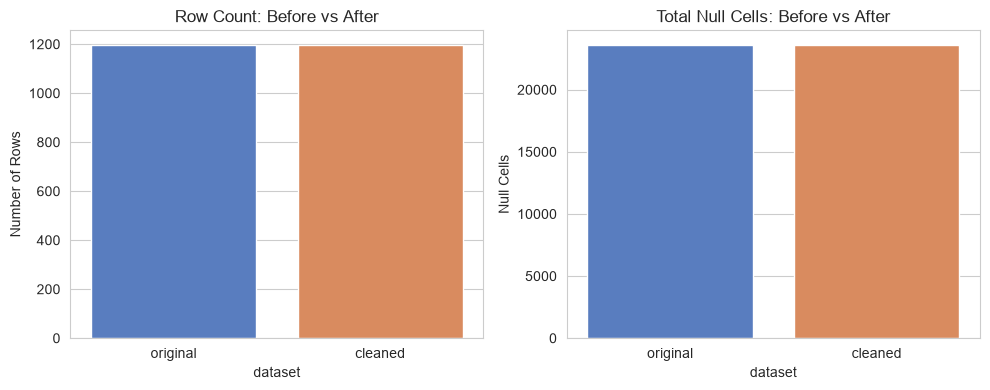

In [13]:
# Before-and-after comparison
def null_summary(d):
    return int(d.isnull().sum().sum())

before_after = pd.DataFrame({
    "dataset": ["original", "cleaned"],
    "n_rows": [len(df_reference), len(df_cleaned)],
    "n_columns": [df_reference.shape[1], df_cleaned.shape[1]],
    "n_unique_sessions": [df_reference["SessionID"].nunique(), df_cleaned["SessionID"].nunique()],
    "total_null_cells": [null_summary(df_reference), null_summary(df_cleaned)],
    "n_excluded": [0, len(df_excluded)],
})
display(before_after)
before_after.to_csv(ANALYSIS_DIR / "preprocessing_before_after.csv", index=False)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x="dataset", y="n_rows", data=before_after, ax=axes[0], palette="muted")
axes[0].set_title("Row Count: Before vs After")
axes[0].set_ylabel("Number of Rows")
sns.barplot(x="dataset", y="total_null_cells", data=before_after, ax=axes[1], palette="muted")
axes[1].set_title("Total Null Cells: Before vs After")
axes[1].set_ylabel("Null Cells")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "preprocessing_before_after.png", bbox_inches="tight")
plt.show()

## Preprocessing report

All preprocessing decisions are recorded in `reports/analysis/preprocessing_report.md`.

In [14]:
# Write preprocessing_report.md
report_lines = [
    "# Preprocessing Report",
    "",
    f"Source file: {DATA_PATH.name}",
    f"Original rows: {report['n_original']:,}",
    f"Cleaned rows: {report['n_cleaned']:,}",
    f"Excluded rows: {report['n_excluded']:,}",
    "",
    "## Transformations applied",
    "1. Timestamp converted from epoch milliseconds to datetime (Timestamp_dt).",
    "2. Events sorted chronologically within each SessionID.",
    "3. Behavioural columns coerced to numeric; non-convertible values -> NaN (reported).",
    "4. Missing values handled per event type; structural nulls left as NaN (not zero).",
    "5. Invalid measurements investigated (negative speed, negative elapsed, null coords on mouse).",
    "6. Invalid records excluded and documented with reasons.",
    "7. Labels/metadata kept separate from behavioural measurements (no target leakage).",
    "",
    "## Exclusion reasons",
]
for reason, n in report["excluded_reasons"]:
    report_lines.append(f"- {reason}: {n} records")
if not report["excluded_reasons"]:
    report_lines.append("- None (no records excluded)")

report_lines += [
    "",
    "## Output files",
    "- dataset/processed/cleaned_events.csv (full cleaned dataset)",
    "- dataset/processed/cleaned_events_ids.csv",
    "- dataset/processed/cleaned_events_labels.csv",
    "- dataset/processed/cleaned_events_metadata.csv",
    "- dataset/processed/cleaned_events_behavioural.csv",
    "- dataset/processed/excluded_records.csv (if any exclusions)",
    "- reports/analysis/preprocessing_before_after.csv",
    "- reports/analysis/preprocessing_assertions.csv",
    "- reports/analysis/preprocessing_numeric_validation.csv",
    "- reports/analysis/preprocessing_missing_by_event_type.csv",
    "- reports/analysis/preprocessing_invalid_measurements.csv",
    "- reports/analysis/preprocessing_target_leakage_check.csv",
    "",
    "## Original data",
    "The original Excel file (dataset/raw/BotPrint_Research_Dataset.xlsx) was not modified.",
]

md_path = ANALYSIS_DIR / "preprocessing_report.md"
md_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Preprocessing report saved to: {md_path}")

# Save cleaned dataset preview
print("\nCleaned dataset head:")
display(df_cleaned.head(5))

Preprocessing report saved to: C:\My KS\Research\BotPrint-Research\reports\analysis\preprocessing_report.md

Cleaned dataset head:


,SessionID,UserType,BotType,SessionSource,BotID,CoordinationGroupID,EventType,Timestamp,ElapsedMs,IdleMs,...,NavigationCount,SessionDurationMs,TotalMouseSamples,TotalClicks,TotalScrolls,TotalTypingEvents,TotalNavigations,Value,Detail,Timestamp_dt
0,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,Manual,NaN,NaN,click,1793721402940,5,5,...,NaN,5,NaN,NaN,NaN,NaN,NaN,BUTTON,NaN,2026-11-03 15:56:42.940
1,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,Manual,NaN,NaN,mousemove,1793721403598,663,100,...,NaN,663,5.0,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-03 15:56:43.598
2,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,Manual,NaN,NaN,mousemove,1793721403899,964,100,...,NaN,964,8.0,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-03 15:56:43.899
3,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,Manual,NaN,NaN,field_interaction,1793721404108,1173,209,...,NaN,1173,NaN,NaN,NaN,NaN,NaN,focusin,NaN,2026-11-03 15:56:44.108
4,S-0108f7d0-0f85-4c15-a643-b0d53c0da2d8,Human,NaN,Manual,NaN,NaN,keypress,1793721405858,2923,1603,...,NaN,2923,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2026-11-03 15:56:45.858
